# Material swatch matching

**Recipe 74 · Level 2 (Easy) · Choice + image criteria**

Sources:

- S02: [TypeSafe primitives](https://docs.typesafe.ai/primitives)
- S03: [TypeSafe confidence](https://docs.typesafe.ai/confidence)
- S09: [TypeSafe images](https://docs.typesafe.ai/images)
- S11: [TypeSafe models](https://docs.typesafe.ai/models)
- S12: [Jev 1.14 release](https://typesafe.ai/blog/jev-1-14)

## What you will build

Build an appearance matcher that compares a query to a controlled collection of four swatch
images. Each `Choice` category is defined by pixels: fictional IDs carry no material taxonomy.
A clear foreign appearance can return `no_match`; obstructed evidence returns `uncertain`.
[Review](../../docs/glossary.md#review) means asking a person to decide, with no resolved match.
Python only records simulated visual suggestions, never purchases or material substitutions.

These are authored synthetic textures, not photographs. Color and pattern likeness cannot
establish fiber content, chemistry, durability, or suitability. The experimental image contract
permits images in criterion values ([S09](https://docs.typesafe.ai/images)); this recipe exercises
that interface offline with invented answers. The committed fixtures contain no model classifications.

## Setup and run mode

A [replay key](../../docs/glossary.md#replay-key) identifies a complete request, including image
bytes. The [provenance](../../docs/glossary.md#provenance) of every committed answer is synthetic:
it was written for this lesson. Offline execution requires no network or key. Switching to live
uses the same questions, image opt-in, and pinned model `jev-1.14.0` ([S11](https://docs.typesafe.ai/models)).
There are 26 requests, each with four references and one query; the answer cache prevents repeat calls.
For live exploration set a request budget of at least 26. See the README for an explicit recorder
workflow; unrecorded live exploration is not a reportable held-out result.

In [1]:
from IPython.display import display
from matplotlib.figure import Figure
from PIL import Image

from jev_cookbook import get_backend, load_helpers
from jev_cookbook.evaluation import (
    accuracy,
    confusion_matrix,
    evaluate_outcomes,
    select_confidence_threshold,
)
from jev_cookbook.fixtures import load_inputs, load_labels, responses_path
from jev_cookbook.simulation import ActionLog, ReviewQueue
from jev_cookbook.style import apply_style, plot_confusion_matrix, run_header, show_answer
from jev_cookbook.vision import run_record

helpers = load_helpers()
examples = load_inputs()
labels = load_labels()
scored = [e for e in examples if e.split in {"validation", "test"}]
backend = get_backend(fixtures=responses_path(), images=True, model="jev-1.14.0")
apply_style()
run_header(74, "Material swatch matching", backend=backend, n_examples=len(scored))
check = " (pipeline check, not a Jev result)" if backend.mode == "synthetic" else ""
selection = " (selection step)"
answers, results = {}, {}


def decide(example):
    if example.id not in results:
        state, questions, assets = helpers.build_request(example.fields)
        results[example.id] = backend.decide(state, questions, assets=assets)
        answers[example.id] = results[example.id]["swatch"]
    return answers[example.id]


def gallery(items, title):
    figure = Figure(figsize=(12, 3.3))
    axes = figure.subplots(1, len(items))
    for ax, (caption, path) in zip(axes, items, strict=True):
        with Image.open(path) as image:
            ax.imshow(image)
        ax.set_title(caption)
        ax.set_axis_off()
    figure.suptitle(title)
    figure.tight_layout()
    return figure

Recipe 74: Material swatch matching
Mode: offline replay of synthetic fixtures, pipeline check on a fixture sample of 24 examples
Metrics in this run are checks that the pipeline works. They are not Jev results.


## The state

The reference panel illustrates two independent traps: M-17 and M-28 share a color but differ
in pattern; M-17 and M-39 share a weave pattern but differ in color. Queries are freshly rendered
patches with different phases, scale, rotation, and lighting. M-46 supplies a dotted surface.
The IDs identify only these pictures; no real manufacturing or material claim is attached.

The model receives `query` as an opaque content reference and a constant task description.
Labels, example IDs, splits, filenames, and drawing parameters remain outside inference.
All images are 384 × 320 upright PNGs; the [local vision helpers](../../docs/vision.md)
validate their sizes and construct assets in memory.

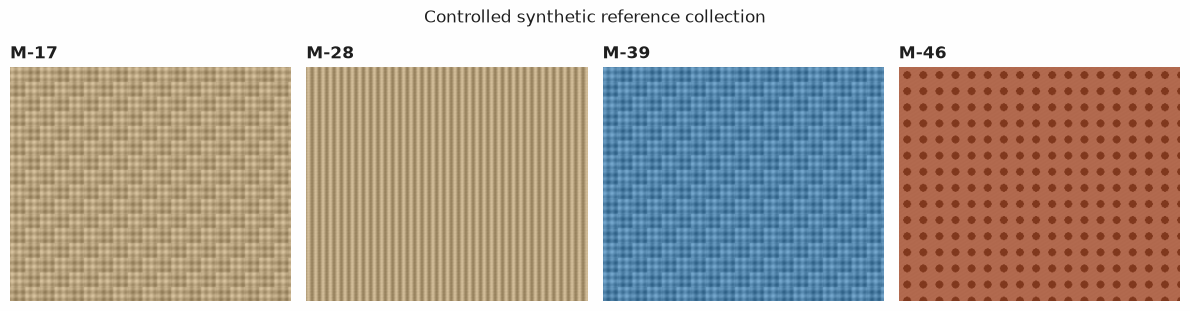

State: {'query': 'image:sha256:a566348a8b0a7ce32f559eaa781dec5f484358bd27058e42e4cadb722cdcce50', 'task': 'Visual appearance match for the supplied reference collection.'}
Assets per request: 5


In [2]:
display(gallery(list(helpers.REFERENCES.items()), "Controlled synthetic reference collection"))
demo = next(e for e in examples if e.id == "d01")
state, questions, assets = helpers.build_request(demo.fields)
print("State:", state)
print("Assets per request:", len(assets))

## The questions

One `Choice` answers one visual comparison: which reference matches both color and texture?
Moderate changes in scale, rotation, and illumination are allowed. A same-color ribbed query
cannot count as the woven reference merely because its average color agrees.

The four criterion values below are actual image references, which the API substitutes with
pixels ([S09](https://docs.typesafe.ai/images)). `no_match` is a complete negative judgment;
`uncertain` means the evidence is obstructed. Text descriptions of these fallbacks explain their
meaning, while the material categories themselves are defined by their pictures.

In [3]:
print(questions["swatch"].to_dict())

{'type': 'choice', 'instructions': 'Which reference has the same visible color and texture as `query`? Allow rotation, moderate scale change, and mild illumination changes. A similar color alone or pattern alone is insufficient. Choose no_match for a clearly different visible swatch, uncertain for obscured evidence. These fictional IDs express appearance only, never composition or suitability.', 'criteria': {'M-17': 'image:sha256:e77d8a8c9f7fdbe9c25bc637874638e59f0a442583c5b98f666c3183af1cbe73', 'M-28': 'image:sha256:438eed34c0aa28ad797add7c19d190470d994459d719b4fd6a39f8ce6d0b422e', 'M-39': 'image:sha256:6499c7a4558e9d223096bcb0d6da922347c14e7ccc6a8d5d172d0f7c9e2aae98', 'M-46': 'image:sha256:a9fbaa79637bf4ddddd2d64ca83eed7082f62b5b1c18a93644a053863e9ffcbd', 'no_match': 'The visible color and texture do not match any supplied reference.', 'uncertain': 'Glare, cover, blur, or conflicting appearance prevents a defensible visual match.'}}


## One answer up close

Inspect the rotated rib texture alongside the same-color woven reference before reading its
typed probabilities. [Confidence](../../docs/glossary.md#confidence) is a value derived from the
answer distribution ([S03](https://docs.typesafe.ai/confidence)), not evidence that a material
is interchangeable with another. The second example deliberately hides the texture under glare.

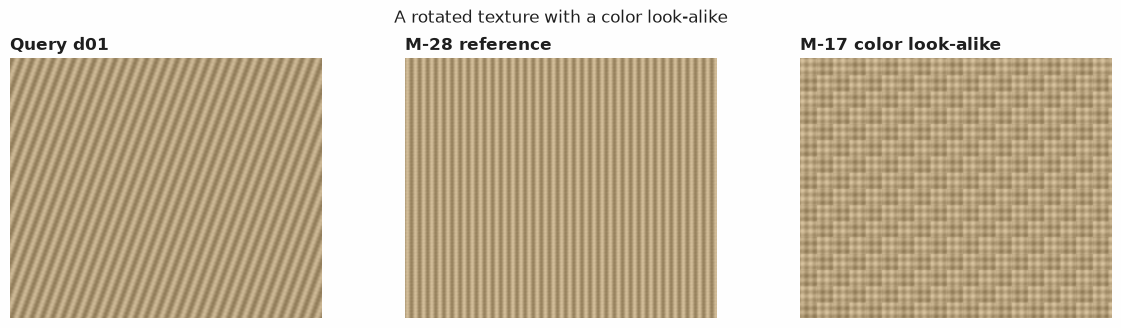

Choice: M-28 (confidence 0.87)
  M-28       0.89  ##################
  M-17       0.02  
  M-39       0.02  
  M-46       0.02  
  no_match   0.02  
  uncertain  0.02  
Provenance: synthetic
Choice: uncertain (confidence 0.92)
  uncertain  0.93  ###################
  M-17       0.01  
  M-28       0.01  
  M-39       0.01  
  M-46       0.01  
  no_match   0.01  
Provenance: synthetic


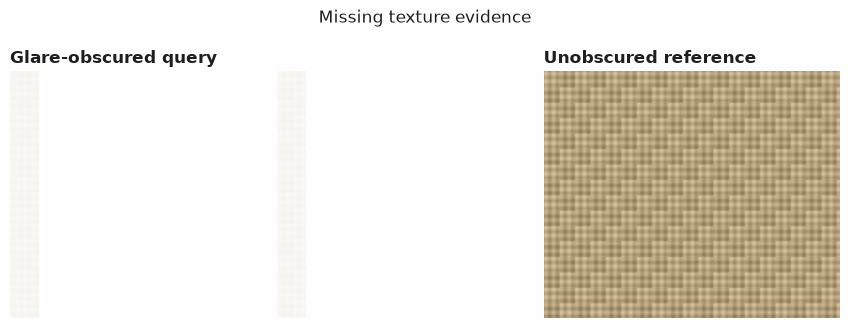

In [4]:
display(
    gallery(
        [
            ("Query d01", demo.fields["image"]),
            ("M-28 reference", helpers.REFERENCES["M-28"]),
            ("M-17 color look-alike", helpers.REFERENCES["M-17"]),
        ],
        "A rotated texture with a color look-alike",
    )
)
show_answer(decide(demo))
obscured = next(e for e in examples if e.id == "d02")
display(
    gallery(
        [
            ("Glare-obscured query", obscured.fields["image"]),
            ("Unobscured reference", helpers.REFERENCES["M-17"]),
        ],
        "Missing texture evidence",
    )
)
show_answer(decide(obscured))

## Python's part

A [confidence gate](../../docs/glossary.md#confidence-gate) accepts an answer only at or above
a frozen threshold. `uncertain` always enters the review queue. Missing, invalid, or low
confidence also defers. `no_match` passes the same gate as a named reference and writes no
candidate suggestion. A candidate only enters an `ActionLog` as a simulated visual suggestion.

A [gold label](../../docs/glossary.md#gold-label) is the authored expected answer. On validation,
choose the lowest observed eligible confidence with at least 90% [accuracy](../../docs/glossary.md#accuracy),
the fraction correct among accepted answers. Exclude unconditional uncertain deferrals from
threshold selection, then evaluate the actual rule on every validation row.
[Coverage](../../docs/glossary.md#coverage) is the fraction accepted; abstention is its complement.
[Risk](../../docs/glossary.md#risk) is the fraction of accepted answers that are wrong. This tiny
validation objective is a selection rule, not a promise about new samples.

The baseline uses mean RGB plus four times mean edge magnitude and twice luminance standard
deviation. Averaging horizontal and vertical edges reduces orientation sensitivity without
making it invariant. A fixed highlight fraction above 25% or luminance deviation below 0.012
forces review. Those gates and feature weights are declared before validation. Select only the
nearest-reference rejection radius from `{0.04, 0.08, 0.12, 0.18, 0.26}`: maximize correct accepts
minus three times wrong accepts, with review worth zero and smaller-radius ties. A radius
rejection returns `no_match`. Both methods see the identical query and reference bytes.

In [5]:
validation = [e for e in examples if e.split == "validation"]
for example in validation:
    decide(example)
eligible = [e for e in validation if answers[e.id].choice != helpers.UNCERTAIN]
threshold = select_confidence_threshold(
    [answers[e.id].choice == labels[e.id] for e in eligible],
    [answers[e.id].confidence for e in eligible],
    target_accuracy=0.9,
)
radius, radius_rows = helpers.choose_radius(validation, labels)
print(
    f"Validation N={len(validation)}, eligible N={len(eligible)}; frozen confidence={threshold:.4f}{selection}{check}"
)
for r, utility, metric in radius_rows:
    print(
        f"Validation N={metric.n_total}; radius={r:.2f}, utility={utility}, accuracy={metric.accuracy:.3f}, coverage={metric.coverage:.3f}{selection}{check}"
    )
print(f"Validation selected radius={radius:.2f}, N={len(validation)}{selection}{check}")
val_decisions = [helpers.route(answers[e.id], threshold) for e in validation]
val_metrics = evaluate_outcomes(
    [d.outcome != helpers.REVIEW for d in val_decisions],
    [d.label == labels[e.id] for e, d in zip(validation, val_decisions, strict=True)],
)
print(
    f"Validation N={val_metrics.n_total}; accuracy={val_metrics.accuracy:.3f}, coverage={val_metrics.coverage:.3f}{selection}{check}"
)
review_queue, action_log = ReviewQueue(), ActionLog()
for example in [demo, obscured]:
    outcome = helpers.apply_decision(
        example.id, answers[example.id], threshold, review_queue, action_log
    )
    print(example.id, outcome)
print("Simulated candidate suggestions:", action_log.to_dicts())
print("Pending review:", review_queue.to_dicts())

Validation N=12, eligible N=10; frozen confidence=0.7960 (selection step) (pipeline check, not a Jev result)
Validation N=12; radius=0.04, utility=2, accuracy=0.800, coverage=0.833 (selection step) (pipeline check, not a Jev result)
Validation N=12; radius=0.08, utility=2, accuracy=0.800, coverage=0.833 (selection step) (pipeline check, not a Jev result)
Validation N=12; radius=0.12, utility=2, accuracy=0.800, coverage=0.833 (selection step) (pipeline check, not a Jev result)
Validation N=12; radius=0.18, utility=6, accuracy=0.900, coverage=0.833 (selection step) (pipeline check, not a Jev result)
Validation N=12; radius=0.26, utility=2, accuracy=0.800, coverage=0.833 (selection step) (pipeline check, not a Jev result)
Validation selected radius=0.18, N=12 (selection step) (pipeline check, not a Jev result)
Validation N=12; accuracy=1.000, coverage=0.667 (selection step) (pipeline check, not a Jev result)
d01 Match(label='M-28', outcome='accepted', reason='visual candidate')
d02 Match(

## Evaluation

The threshold and radius are now frozen. Open the twelve held-out test queries once and compare
raw six-way accuracy plus accepted accuracy, coverage, abstention, review counts, and accepted
errors. Shared `evaluate_outcomes` receives the actual accept flags, so an accurately predicted
`uncertain` still counts as review. The raw confusion matrix includes that class to show the
visual judgment separately from the Python acceptance decision.

The two input sets were authored independently but share the same small synthetic drawing
family. These figures check code paths, not generalization to photography or Jev quality.

In [6]:
test_examples = [e for e in examples if e.split == "test"]
for example in test_examples:
    decide(example)
gold = [labels[e.id] for e in test_examples]
choice_decisions = [helpers.route(answers[e.id], threshold) for e in test_examples]
baseline_decisions = [helpers.baseline(e.fields, radius) for e in test_examples]
comparisons = [
    ("Image Choice replay", choice_decisions),
    ("RGB + texture baseline", baseline_decisions),
]
if backend.mode == "live":
    print(f"N={len(test_examples)} unrecorded test exploration; aggregate reporting disabled.")
else:
    for name, decisions in comparisons:
        predicted = [d.label for d in decisions]
        correct = [a == b for a, b in zip(gold, predicted, strict=True)]
        accepted = [d.outcome != helpers.REVIEW for d in decisions]
        metric = evaluate_outcomes(accepted, correct)
        accepted_errors = sum(a and not c for a, c in zip(accepted, correct, strict=True))
        print(
            f"Test {name}: N={len(gold)}, raw accuracy={accuracy(gold, predicted):.3f}, accepted N={metric.n_answered}, accepted accuracy={metric.accuracy:.3f}, coverage={metric.coverage:.3f}, abstention={1 - metric.coverage:.3f}, risk={metric.risk:.3f}, reviews={len(gold) - metric.n_answered}, accepted errors={accepted_errors}{check}"
        )
    print("Paired decisions (ID, gold, Choice/outcome, baseline/outcome):")
    for e, first, second in zip(test_examples, choice_decisions, baseline_decisions, strict=True):
        print(e.id, labels[e.id], first.label, first.outcome, second.label, second.outcome)

Test Image Choice replay: N=12, raw accuracy=0.917, accepted N=8, accepted accuracy=0.875, coverage=0.667, abstention=0.333, risk=0.125, reviews=4, accepted errors=1 (pipeline check, not a Jev result)
Test RGB + texture baseline: N=12, raw accuracy=0.917, accepted N=10, accepted accuracy=0.900, coverage=0.833, abstention=0.167, risk=0.100, reviews=2, accepted errors=1 (pipeline check, not a Jev result)
Paired decisions (ID, gold, Choice/outcome, baseline/outcome):
t01 M-17 M-17 accepted M-17 accepted
t02 M-28 M-28 accepted M-28 accepted
t03 M-39 M-39 accepted M-39 accepted
t04 M-46 M-46 accepted M-46 accepted
t05-scale M-17 M-17 review M-17 accepted
t06-light M-39 M-39 review no_match accepted
t07-lookalike M-28 M-17 accepted M-28 accepted
t08-unknown no_match no_match accepted no_match accepted
t09-recolor no_match no_match accepted no_match accepted
t10-glare uncertain uncertain review uncertain review
t11-cover uncertain uncertain review uncertain review
t12-turn M-46 M-46 accepted 

Test N=12 raw Choice matrix, gold rows/predicted columns (pipeline check, not a Jev result)
['M-17', 'M-28', 'M-39', 'M-46', 'no_match', 'uncertain'] [[2 0 0 0 0 0]
 [1 1 0 0 0 0]
 [0 0 2 0 0 0]
 [0 0 0 2 0 0]
 [0 0 0 0 2 0]
 [0 0 0 0 0 2]]


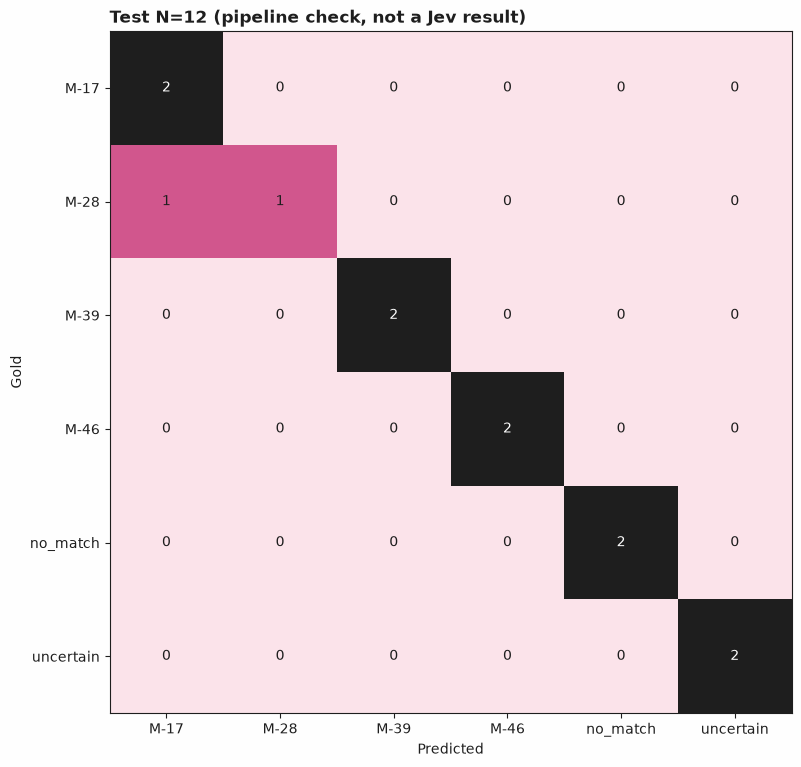

In [7]:
if backend.mode != "live":
    matrix = confusion_matrix(
        gold, [answers[e.id].choice for e in test_examples], labels=list(helpers.OPTIONS)
    )
    print(f"Test N={len(test_examples)} raw Choice matrix, gold rows/predicted columns{check}")
    print(matrix.labels, matrix.matrix)
    display(plot_confusion_matrix(matrix, title=f"Test N={len(test_examples)}{check}"))

### Inspect the accepted error

This held-out texture look-alike has the same color as M-17 but a rotated rib pattern matching
M-28. In the committed synthetic replay, the invented answer assigns M-17 high confidence.
The frozen policy accepts it: confidence
cannot repair a wrong visual judgment. This is intentionally visible in the matrix and accepted
error count, rather than making every synthetic mistake easy to catch.

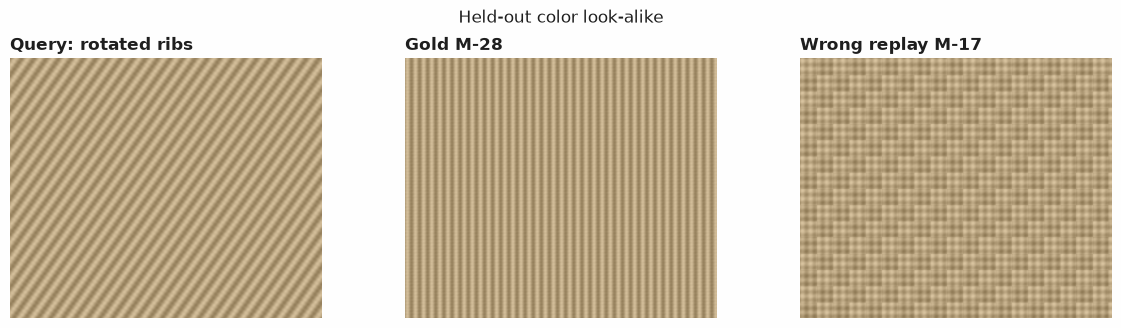

Choice: M-17 (confidence 0.94)
  M-17       0.95  ###################
  M-28       0.01  
  M-39       0.01  
  M-46       0.01  
  no_match   0.01  
  uncertain  0.01  
Provenance: synthetic
Python outcome: Match(label='M-17', outcome='accepted', reason='visual candidate')


In [8]:
hard = next(e for e in test_examples if e.id == "t07-lookalike")
display(
    gallery(
        [
            ("Query: rotated ribs", hard.fields["image"]),
            ("Gold M-28", helpers.REFERENCES["M-28"]),
            ("Wrong replay M-17", helpers.REFERENCES["M-17"]),
        ],
        "Held-out color look-alike",
    )
)
show_answer(answers[hard.id])
print("Python outcome:", helpers.route(answers[hard.id], threshold))

## What was and was not measured

The following cell prints mode and N in every run, plus the returned model and capture date
when answers were recorded. N is twelve validation plus twelve test examples; the two demos
are unscored. Synthetic numbers are pipeline checks. Tokens, inference latency, and cost stay
`None` when not measured. Replay wall time is not inference latency. Recorded measurements
would describe only these synthetic-image samples; unrecorded live runs are exploration.

For actual photography, build a new acquisition protocol and independently labeled split.
Keep unknown textures, severe glare, partial covers, white-balance drift, and same-color
competitors. The current tiny reference collection cannot certify material identity.

In [9]:
if backend.mode == "synthetic":
    print("Mode: synthetic. Not measured live: a pipeline check, not a Jev result.")
    print(f"N: {len(scored)} scored; validation=12, test=12; demos=2.")
elif backend.mode == "recorded":
    print(f"Mode: recorded; model={backend.model}; capture dates={backend.recorded_dates}.")
    print(f"N: {len(scored)} scored; validation=12, test=12; demos=2.")
else:
    print(
        f"Mode: live exploration; returned model={backend.model}; no reportable held-out results."
    )
    print(f"N: {len(scored)} scored; validation=12, test=12; demos=2.")
print("Requests completed:", len(results), "; images per request: 5; unique image files: 30")
print("One accounting row:", run_record(results[demo.id], mode=backend.mode))

Mode: synthetic. Not measured live: a pipeline check, not a Jev result.
N: 24 scored; validation=12, test=12; demos=2.
Requests completed: 26 ; images per request: 5; unique image files: 30
One accounting row: {'model': None, 'input_tokens': None, 'output_tokens': None, 'latency_seconds': None, 'cost_usd': None, 'mode': 'synthetic'}


## Next steps

Try fixed camera distance and a white-balance target with a licensed, independently photographed
collection. Keep reference and query photographs distinct. Add non-catalog colors and texture
families before tuning on new validation data, then inspect held-out mistakes only after freezing
both policies. A texture-aware baseline may need a scale-normalized descriptor; measure that
choice on a fresh split rather than adapting it to these test images.

Continue with [abstention and review queues](../38-abstention-and-review-queues/) for explicit
human deferral and [sentiment classification](../01-sentiment-classification/) for the typed
Choice evaluation pattern. The [live recorder](../../docs/live.md) captures actual returned
model/date/usage; retain actual latency only when measured and leave unknown cost unset.